In [ ]:
import os
import sys
from pathlib import Path

import src
import keras
import tensorflow as tf
import pandas as pd

from src.config import SEED, ensure_directories, set_global_seed

ensure_directories()
set_global_seed(SEED)
accel_info = f"TF devices: {tf.config.list_physical_devices()}"
if keras.backend.backend() == "torch":
    import torch
    mps_ok = torch.backends.mps.is_available()
    accel_info = f"Apple Metal GPU (MPS): {'ACTIVE' if mps_ok else 'CPU'} (torch {torch.__version__})"
print(f"Keras: {keras.__version__} (backend={keras.backend.backend()}) | TensorFlow: {tf.__version__}")
print(f"Апаратне прискорення: {accel_info}")


Keras: 3.15.1 (backend=torch) | TensorFlow: 2.21.0
Апаратне прискорення: Apple Metal GPU (MPS): ACTIVE (torch 2.15.0)


In [2]:
from src.data_prep import prepare_dataset_splits, prepare_external_test_images
from src.dataset import summarize_splits_dataframe
from src.visualization import plot_sample_images

split_stats = prepare_dataset_splits()
external_records = prepare_external_test_images()

print(f"Усього валідних зображень: {split_stats['total_valid']}")
print(f"Відсіяно пошкоджених файлів: {len(split_stats['corrupted_files'])} -> {split_stats['corrupted_files'][:5]}")
print(f"Стандартизовано у чистий 3-канальний RGB JPEG: {split_stats['reencoded_count']}")

df_splits = summarize_splits_dataframe()
display(df_splits)


[data_prep] Existing split found (24997 valid images). Skipping re-split.
[data_prep] External test set ready (10 images).
Усього валідних зображень: 24997
Відсіяно пошкоджених файлів: 3 -> [{'file': 'Cat/5673.jpg', 'reason': 'dimensions_too_small_4x4'}, {'file': 'Cat/666.jpg', 'reason': 'empty_or_tiny_file'}, {'file': 'Dog/11702.jpg', 'reason': 'empty_or_tiny_file'}]
Стандартизовано у чистий 3-канальний RGB JPEG: 255


,Split,Cats (0),Dogs (1),Total,Dog Ratio (%)
0,train,9998,9999,19997,50.0
1,val,1249,1249,2498,50.0
2,test,1251,1251,2502,50.0
3,TOTAL,12498,12499,24997,50.0


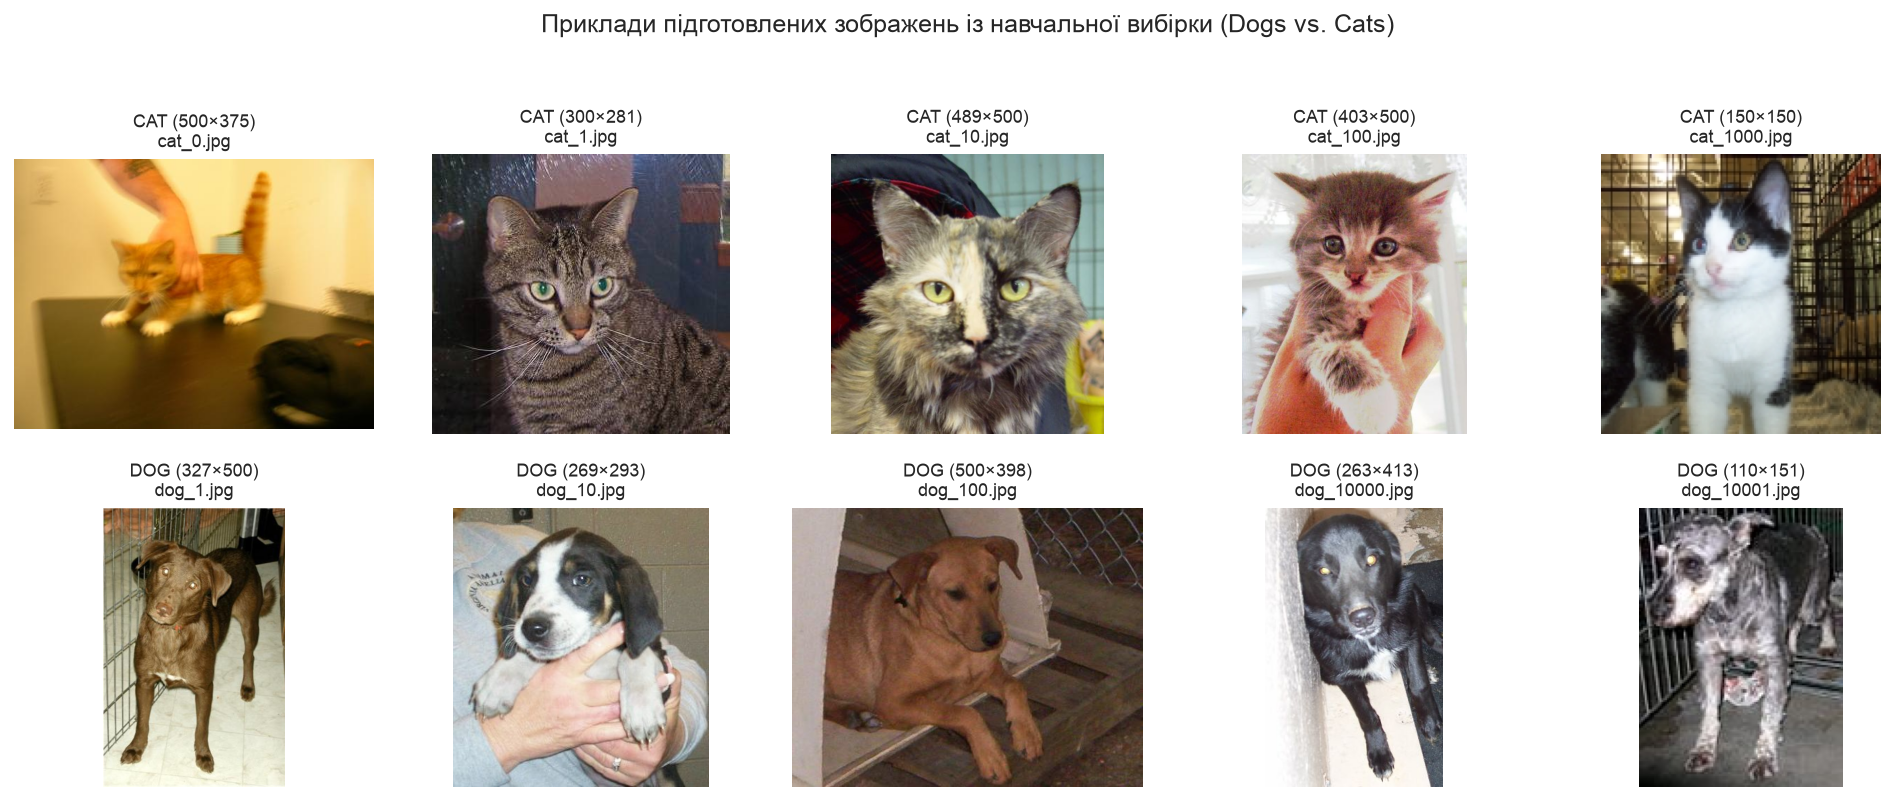

In [ ]:
plot_sample_images()

In [ ]:
from src.trainer import extract_or_load_features

vgg_features, vgg_extract_sec = extract_or_load_features("vgg16")
print(f"Форма ознак train: {vgg_features['train'][0].shape}, час екстракції: {vgg_extract_sec:.1f} с")

Found 19997 files belonging to 2 classes.
Found 2498 files belonging to 2 classes.
Found 2502 files belonging to 2 classes.
[trainer] Extracting frozen features for 'train' split ...
[trainer] Extracting frozen features for 'val' split ...
[trainer] Extracting frozen features for 'test' split ...
Форма ознак train: (19997, 512), час екстракції: 601.3 с


MPS GPU [test]: 100%|##########| 79/79 [01:01<00:00,  1.27it/s]


In [5]:
from src.config import DROPOUT_EXPERIMENTS
from src.trainer import release_memory, train_head_experiment

dropout_heads = {}
dropout_records = []

for rate in DROPOUT_EXPERIMENTS:
    release_memory()
    head_model, rec = train_head_experiment(
        model_key="vgg16",
        features=vgg_features,
        dropout_rate=rate,
        epochs=20,
        restore_best_weights=True,
    )
    dropout_heads[rate] = head_model
    dropout_records.append(rec)
    print(
        f"Dropout={rate:.1f} | Best Epoch={rec['best_epoch']:2d} | "
        f"Best Val Acc={rec['best_val_accuracy']*100:.2f}% | "
        f"Test Acc={rec['test_metrics']['accuracy']*100:.2f}% | "
        f"Overfit Acc Gap={rec['overfitting_acc_gap']*100:+.2f}%"
    )


Dropout=0.0 | Best Epoch= 1 | Best Val Acc=98.72% | Test Acc=98.24% | Overfit Acc Gap=+1.31%
Dropout=0.2 | Best Epoch= 9 | Best Val Acc=98.76% | Test Acc=98.40% | Overfit Acc Gap=+1.16%
Dropout=0.5 | Best Epoch= 5 | Best Val Acc=98.92% | Test Acc=98.64% | Overfit Acc Gap=+0.95%
Dropout=0.7 | Best Epoch= 4 | Best Val Acc=98.88% | Test Acc=98.84% | Overfit Acc Gap=+0.60%


In [6]:
df_dropout = pd.DataFrame(
    [
        {
            "Dropout": r["dropout_rate"],
            "Best Epoch": r["best_epoch"],
            "Final Train Acc (%)": round(r["final_train_accuracy"] * 100, 2),
            "Final Val Acc (%)": round(r["final_val_accuracy"] * 100, 2),
            "Overfitting Gap (%)": round(r["overfitting_acc_gap"] * 100, 2),
            "Best Val Loss": r["best_val_loss"],
            "Test Accuracy (%)": round(r["test_metrics"]["accuracy"] * 100, 2),
            "Test ROC-AUC": r["test_metrics"]["roc_auc"],
            "Test F1": r["test_metrics"]["f1"],
        }
        for r in dropout_records
    ]
)
display(df_dropout)


,Dropout,Best Epoch,Final Train Acc (%),Final Val Acc (%),Overfitting Gap (%),Best Val Loss,Test Accuracy (%),Test ROC-AUC,Test F1
0,0.0,1,99.98,98.68,1.31,0.04493,98.24,0.99799,0.98241
1,0.2,9,99.88,98.72,1.16,0.04488,98.40,0.99881,0.98390
2,0.5,5,99.59,98.64,0.95,0.03829,98.64,0.99897,0.98632
3,0.7,4,99.20,98.60,0.60,0.03603,98.84,0.99892,0.98838


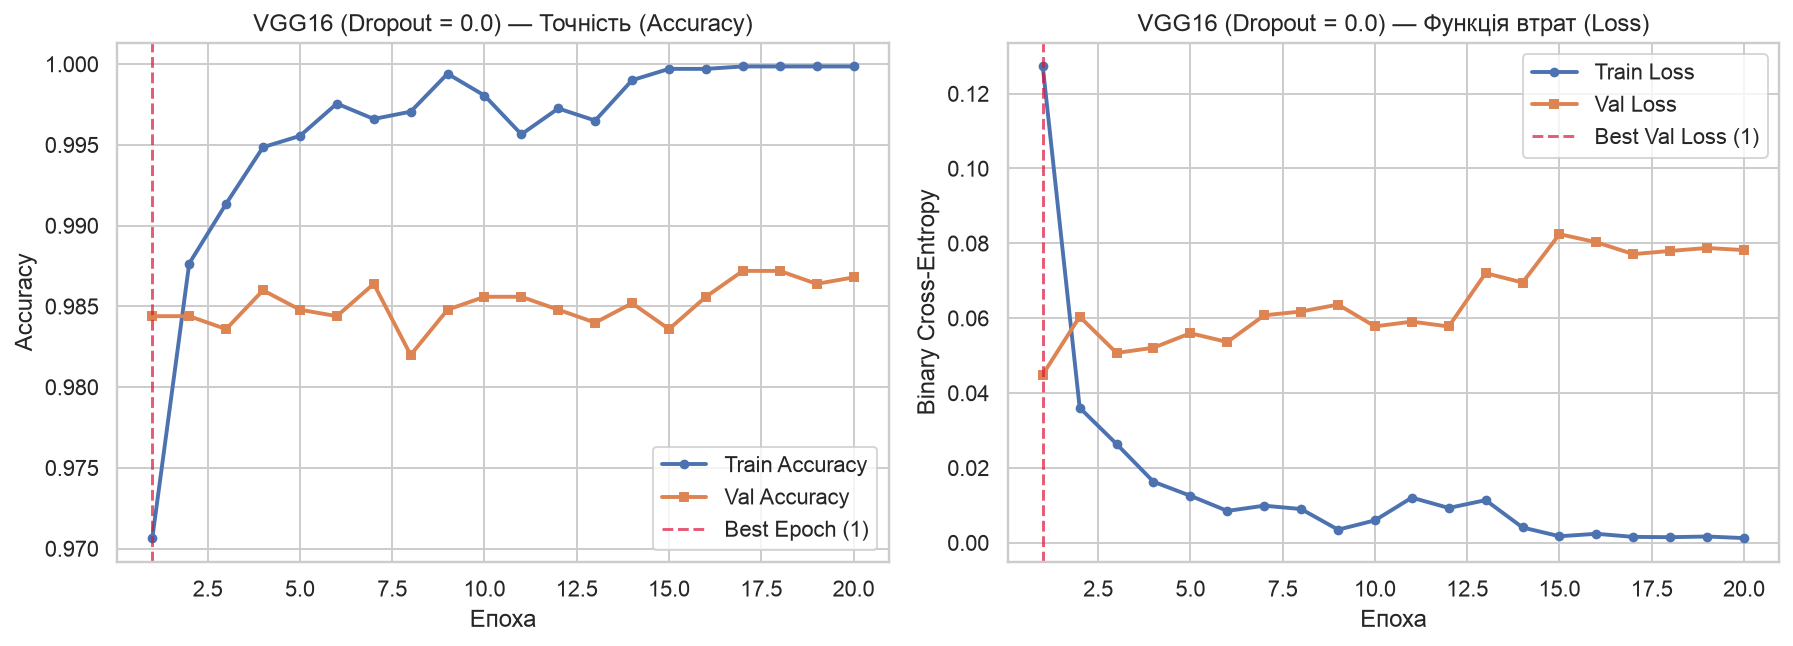

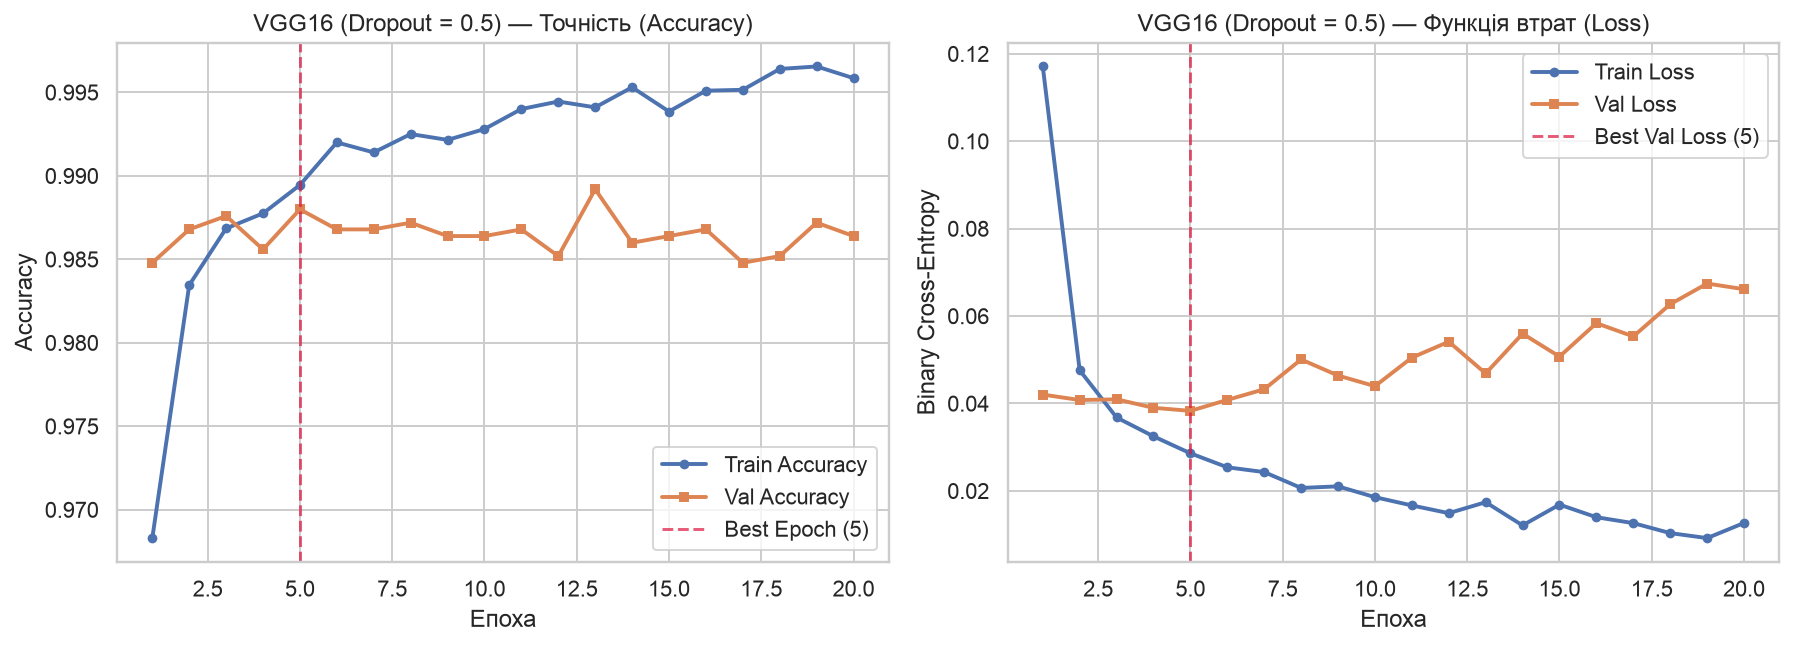

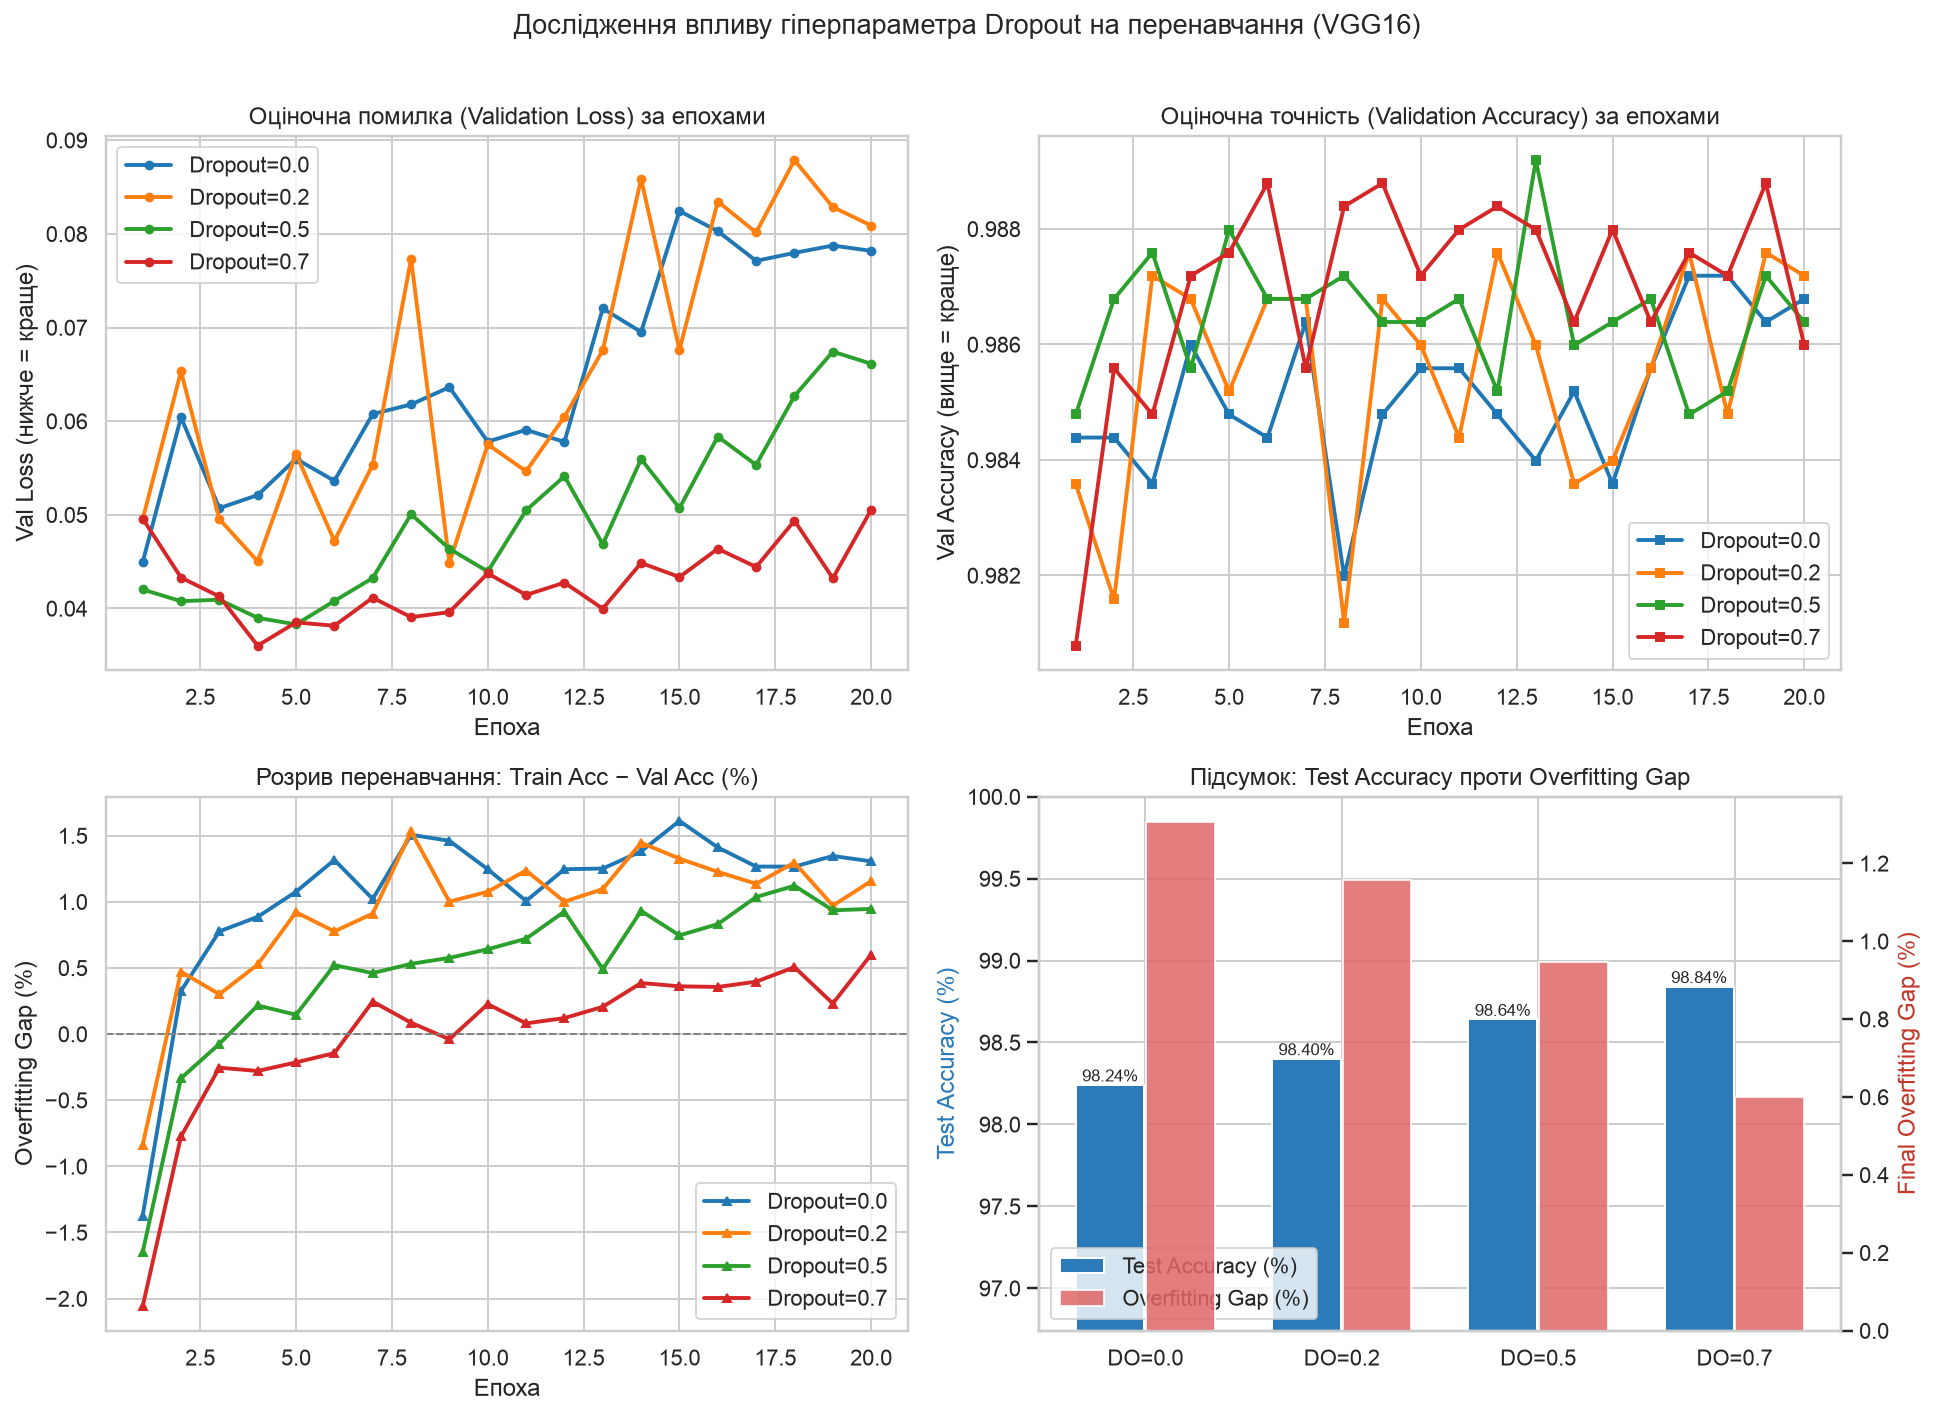

In [ ]:
from src.visualization import plot_dropout_comparison, plot_training_curves

plot_training_curves(dropout_records[0], save_name="01_vgg16_curves_do_0_0.png")
plot_training_curves(dropout_records[2], save_name="01_vgg16_curves_do_0_5.png")
plot_dropout_comparison(dropout_records, save_name="01_vgg16_dropout_comparison.png")

Обрано оптимальний Dropout = 0.7 (Best Val Loss = 0.03603)
Model: "vgg16_transfer_learning"
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_rgb           │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ input_rgb[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ input_rgb[0][0]   │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ inpu

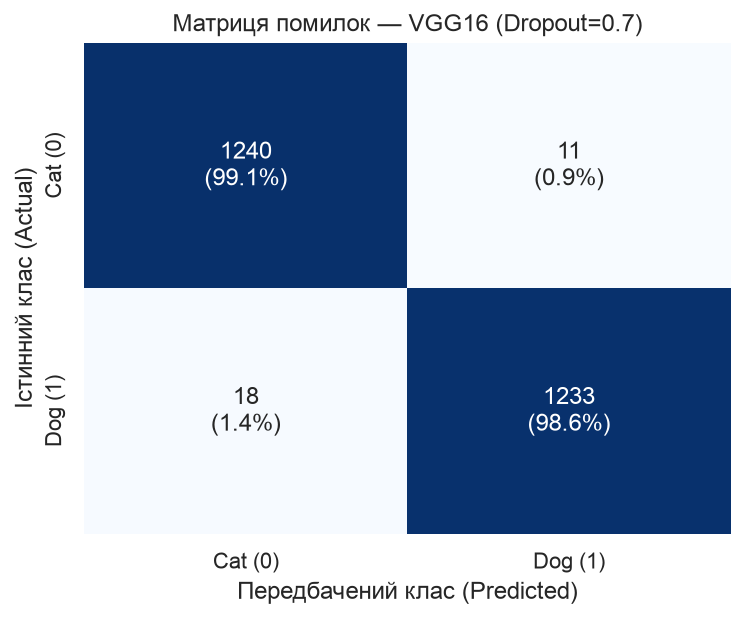

In [ ]:
from src.config import MODELS_DIR
from src.models_factory import assemble_end_to_end_model
from src.trainer import finalize_and_save_model, predict_external_images
from src.visualization import plot_confusion_matrix, plot_external_predictions_grid

best_record = min(dropout_records, key=lambda r: r["best_val_loss"])
best_rate = best_record["dropout_rate"]
print(f"Обрано оптимальний Dropout = {best_rate} (Best Val Loss = {best_record['best_val_loss']:.5f})")

preview_model = assemble_end_to_end_model("vgg16", dropout_heads[best_rate], dropout_rate=best_rate)
preview_model.summary()
del preview_model

vgg_final = finalize_and_save_model(
    model_key="vgg16",
    trained_head=dropout_heads[best_rate],
    experiment_record=best_record,
    extraction_seconds=vgg_extract_sec,
)

plot_confusion_matrix(
    vgg_final["test_metrics"]["confusion_matrix"],
    model_title=f"VGG16 (Dropout={best_rate})",
    save_name="01_vgg16_confusion_matrix.png",
)


/Users/bohdan_best/Documents/університет/4 курс/Deep Learning/lab8/.venv/lib/python3.13/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_2', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


,filename,rel_path,true_class,pred_class,dog_probability,confidence,correct
0,ext_cat_01_tabby.jpg,cats/ext_cat_01_tabby.jpg,cats,cats,0.0001,0.9999,True
1,ext_cat_02_orange.jpg,cats/ext_cat_02_orange.jpg,cats,cats,0.0065,0.9935,True
2,ext_cat_03_white_cat.jpg,cats/ext_cat_03_white_cat.jpg,cats,cats,0.0000,1.0000,True
3,ext_cat_04_kitten.jpg,cats/ext_cat_04_kitten.jpg,cats,cats,0.0000,1.0000,True
4,ext_cat_05_portrait.jpg,cats/ext_cat_05_portrait.jpg,cats,cats,0.0000,1.0000,True
5,ext_dog_01_golden_retriever.jpg,dogs/ext_dog_01_golden_retriever.jpg,dogs,dogs,1.0000,1.0000,True
6,ext_dog_02_samoyed.jpg,dogs/ext_dog_02_samoyed.jpg,dogs,dogs,0.9803,0.9803,True
7,ext_dog_03_beagle.jpg,dogs/ext_dog_03_beagle.jpg,dogs,dogs,1.0000,1.0000,True
8,ext_dog_04_german_shepherd.jpg,dogs/ext_dog_04_german_shepherd.jpg,dogs,dogs,1.0000,1.0000,True
9,ext_dog_05_pug.jpg,dogs/ext_dog_05_pug.jpg,dogs,dogs,0.9529,0.9529,True


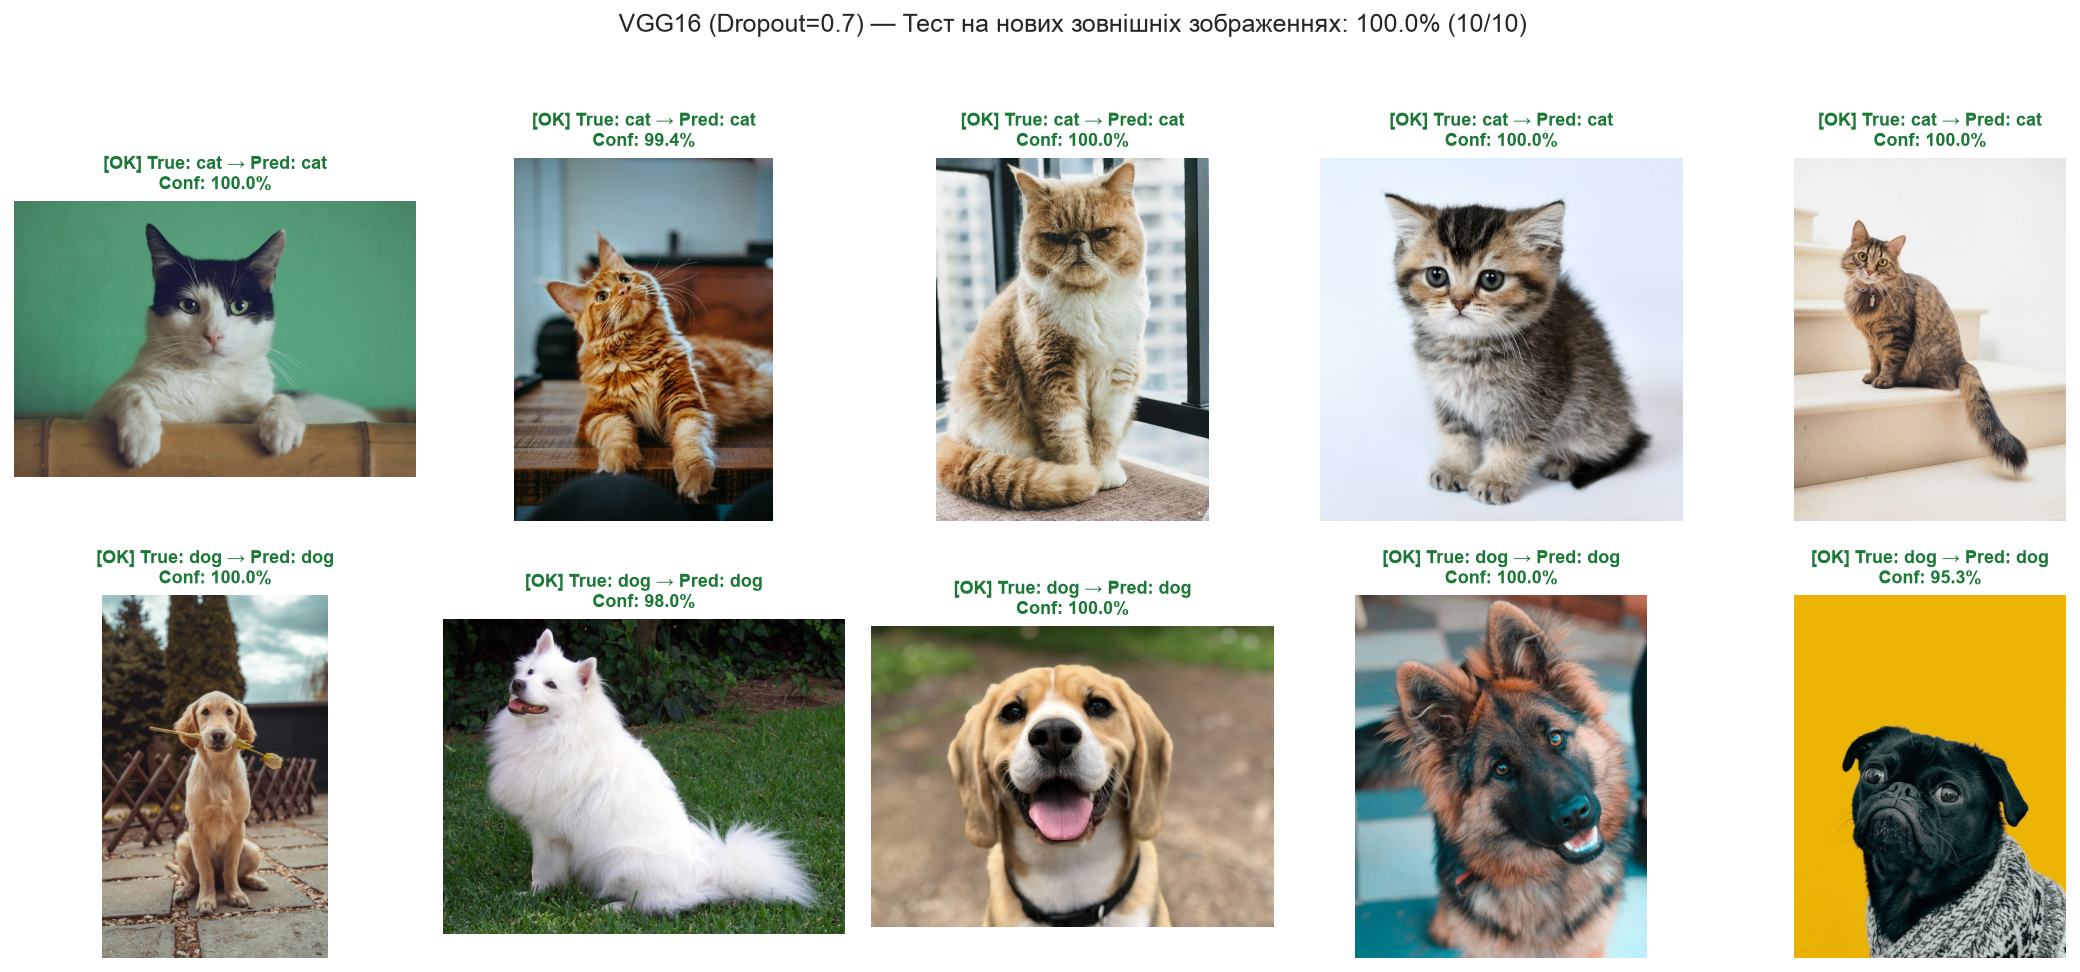

In [ ]:
df_ext_vgg = predict_external_images(MODELS_DIR / "vgg16_best.keras")
display(df_ext_vgg)
plot_external_predictions_grid(
    df_ext_vgg,
    model_title=f"VGG16 (Dropout={best_rate})",
    save_name="01_vgg16_external_test.png",
)